# Plotting uncertaintites in slope

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

co2 = pd.read_csv("../../course-materials/week10/co2_maunaloa_annual.csv", header=None, names=["year", "ppm"])

co2.tail(3)

,year,ppm
61,2020,414.21
62,2021,416.41
63,2022,418.53


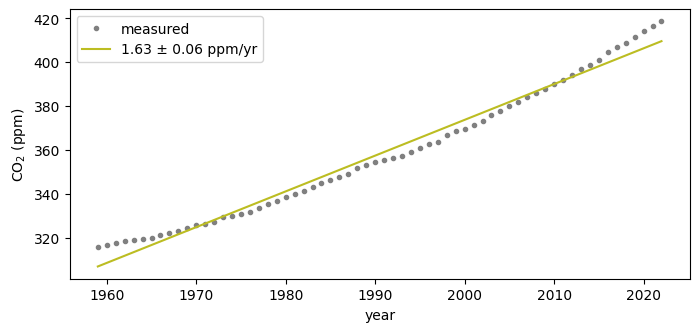

In [4]:
result = stats.linregress(co2["year"], co2["ppm"])
slope = result.slope
uncertainty = 2 * result.stderr
fitted = result.slope * co2["year"] + result.intercept

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")

ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

In [5]:
year_mid = co2["year"].mean()
ppm_mid = co2["ppm"].mean()

In [6]:
steep = ppm_mid + (slope + uncertainty) * (co2["year"] - year_mid)
shallow = ppm_mid + (slope - uncertainty) * (co2["year"] - year_mid)

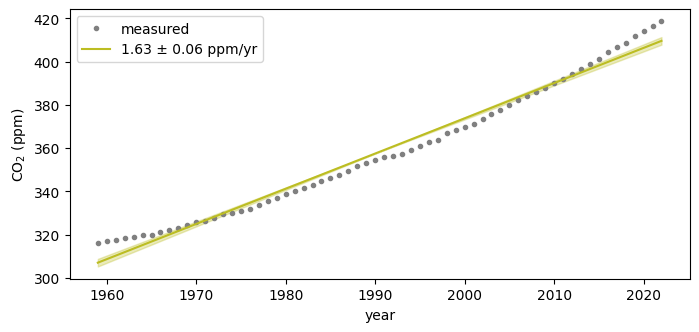

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
ax.fill_between(co2["year"], shallow, steep, color="tab:olive", alpha=0.3)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

You can use `ax.fill_between()` to shade the area between two curves, so you need a top edge and a bottom edge.

**Why can't you just do `fitted +/- 0.6`?**

Your +/- 0.06 is the uncertainty on the **slope**, in ppm per year. It isn't +/- 0.06 ppm on the CO2 values. If you shaded `fitted + 0.06` to `fitted - 0.06`, the band would be tinner than teh line and you wouldn't see it.

What the +/-0.06 tells you is that the true line could be a little steeper (1.69 ppm/yr) or a little shallower (1.57 ppm/yr). The shaded region should cover the space between those two lines. So. Do the following steps:

1. **Find the middle of your data**
   
A fitted line always goes through the average `x` and the average `y`, so taht's the point where the steeper and shallower lines should cross.
```python
year_mid = co2["year"].mean()
ppm_mid = co2["ppm"].mean()
```
2. **Build the steeper and shallower lines**
   
This is the "point-slope" form: start at the middle point, then go up or down by slope x distance from the middle.
```python
steep = ppm_mid + (slope + uncertainty) * (co2["year"] - year_mid)
shallow = ppm_mid + (slope - uncertainty) *(co2["year"] - year_mid)
```
3. **Add the shading to your plot**

Put this right after your two `ax.plot(...)` lines:
```python
ax.fill_between(co2["year"], shallow, steep, color="tab:olive", alpha=0.3)
```

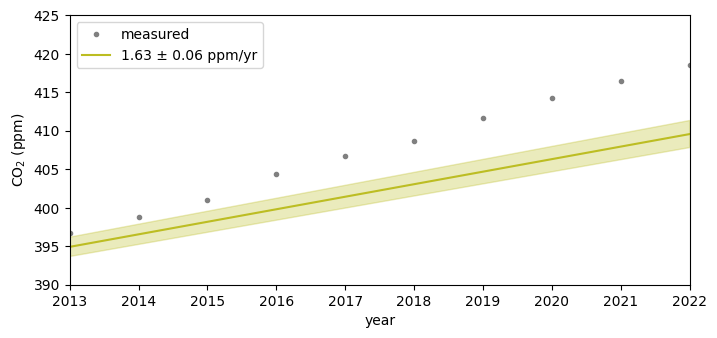

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
ax.fill_between(co2["year"], shallow, steep, color="tab:olive", alpha=0.3)

ax.set_xlim(2013, 2022)
ax.set_ylim(390, 425)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

### What if we only look at the last 10 years?

In [13]:
recent = co2[co2["year"] >= 2013]

recent_result = stats.linregress(recent["year"], recent["ppm"])
recent_slope = recent_result.slope
recent_uncertainty = 2 * recent_result.stderr
recent_fitted = recent_result.slope * co2["year"] + recent_result.intercept

print(f"2013-2022: {recent_slope:.2f} ± {recent_uncertainty:.2f} ppm per year")

2013-2022: 2.48 ± 0.07 ppm per year


In [16]:
year_mid_recent = recent["year"].mean()
ppm_mid_recent = recent["ppm"].mean()

In [18]:
steep_recent = ppm_mid_recent + (recent_slope + recent_uncertainty) * (recent["year"] - year_mid_recent)
shallow_recent = ppm_mid_recent + (recent_slope - recent_uncertainty) * (recent["year"] - year_mid_recent)

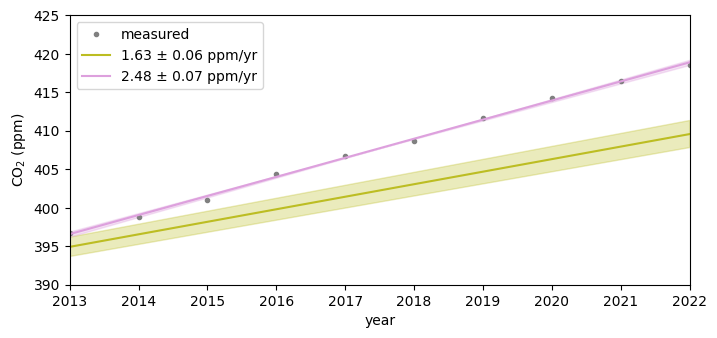

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
ax.plot(co2["year"], recent_fitted, color="plum", label=f"{recent_slope:.2f} ± {recent_uncertainty:.2f} ppm/yr")

ax.fill_between(co2["year"], shallow, steep, color="tab:olive", alpha=0.3)
ax.fill_between(recent["year"], shallow_recent, steep_recent, color="plum", alpha=0.3)

ax.set_xlim(2013, 2022)
ax.set_ylim(390, 425)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

### This band only shows the slope uncertainty.

A full "confidence band" also includes the intercept uncertainty and comes out slightly curved instead of a bowtime. The bowtie is the standard easy-to-explain version.

The full band combines two kinds of uncertainty:
1. **How high or low the line sits overall**. This is the intercept part, and it sets the band's width in the middle.
2. **How tilted the line is**. THis is the slope part above. it makes the band wider towards the ends.

Together they give a band that's narrowest at the middle of your data and curves outward toward both ends, sort of like an hourglass lying on its side.

#### Step 1 : find how far each point is from the line

In [22]:
residuals = co2["ppm"] - fitted

#### Step 2 : turn the residuals into one "typical scatter" number

In [23]:
n = len(co2)
s = np.sqrt(np.sum(residuals**2) / (n -2))

#### Step 3: measure how spread out your years are

In [24]:
year_mean = co2["year"].mean()
year_spread = np.sum((co2["year"] - year_mean)**2)

#### Step 4: calculate the uncertainty at every year

In [25]:
se_fit = s * np.sqrt(1/n + (co2["year"] - year_mean)**2 / year_spread)

#### Step 5: shade it

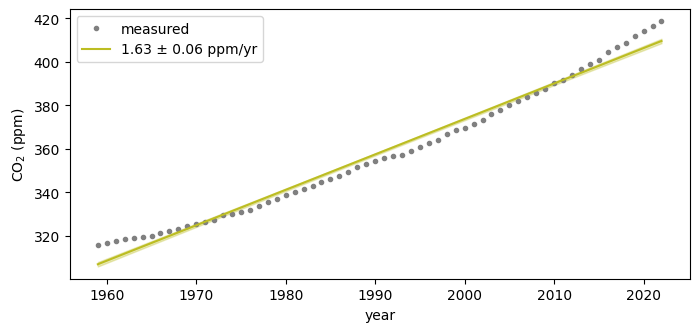

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
#ax.fill_between(co2["year"], shallow, steep, color="tab:olive", alpha=0.3)
ax.fill_between(co2["year"], fitted - se_fit, fitted + se_fit,color="tab:olive", alpha=0.3)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

or you can use stats

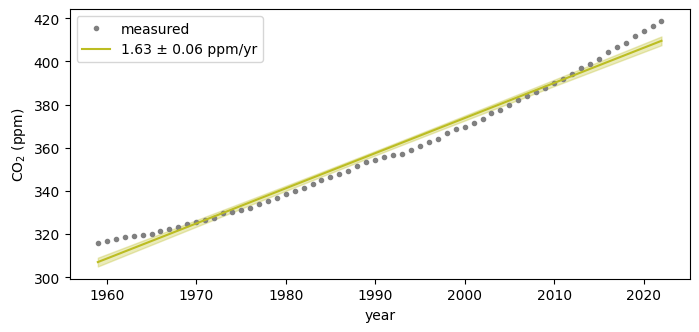

In [27]:
from scipy.stats import t
t_crit = t.ppf(0.975, n-2)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
ax.fill_between(co2["year"], fitted - t_crit * se_fit, fitted + t_crit * se_fit,
                color="tab:olive", alpha=0.3)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

### What if we have uncertainty per point?

In [28]:
co2["ppm_unc"] = np.linspace(3, 1, len(co2))

#### Option 1 : Error Bars

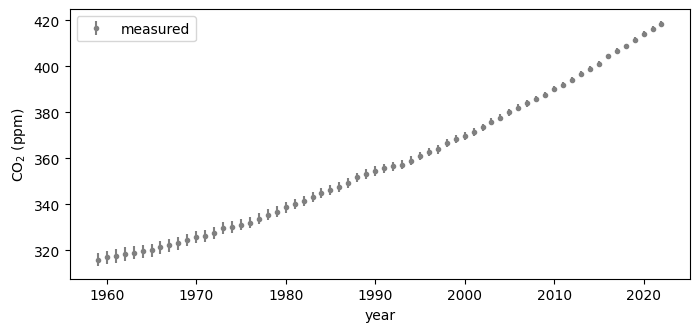

In [30]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(co2["year"], co2["ppm"], yerr=co2["ppm_unc"], fmt="o", markersize=3, color="gray", label="measured")
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

#### Option 2 : a shaded band

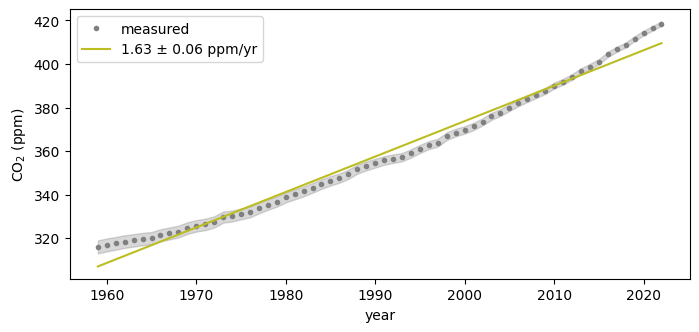

In [31]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
ax.fill_between(co2["year"], co2["ppm"] - co2["ppm_unc"], co2["ppm"] + co2["ppm_unc"],color="gray", alpha=0.3)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

#### Is there a way to find the best fit given those uncertainties?

**weighted least squares**: lets points with small uncertainty pull harder on the line, and points with big uncertainties count less

In [33]:
from scipy.optimize import curve_fit

`curve_fit` needs your model written as a python function. So for a straight line:

In [34]:
def line(x, m, b):
    return m * x + b

then we can do the fit

In [36]:
params, cov = curve_fit(line, co2["year"], co2["ppm"], sigma=co2["ppm_unc"], absolute_sigma=True)

and pull out the numbers

In [37]:
slope_w, intercept_w = params
slope_w_unc = np.sqrt(cov[0, 0])
print(f"{slope_w:.2f} ± {slope_w_unc:.2f} ppm/yr")

1.75 ± 0.01 ppm/yr


and plot it

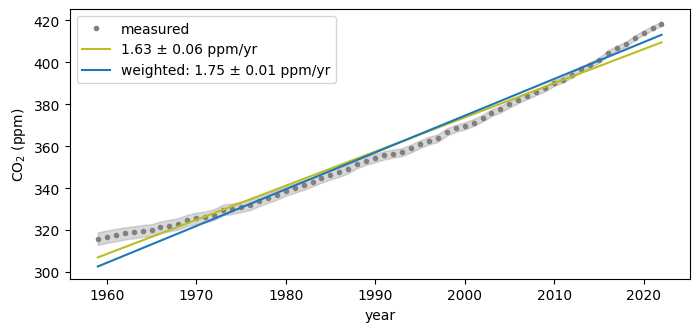

In [41]:
fitted_w = line(co2["year"], slope_w, intercept_w)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(co2["year"], co2["ppm"], "o", markersize=3, color="gray", label="measured")
ax.plot(co2["year"], fitted, color="tab:olive", label=f"{slope:.2f} ± {uncertainty:.2f} ppm/yr")
ax.plot(co2["year"], fitted_w, color="tab:blue", label=f"weighted: {slope_w:.2f} ± {slope_w_unc:.2f} ppm/yr")
ax.fill_between(co2["year"], co2["ppm"] - co2["ppm_unc"], co2["ppm"] + co2["ppm_unc"],color="gray", alpha=0.3)
ax.set_xlabel("year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend();

and we can check to see if the fit makes sense

In [43]:
n = len(co2)
chi2 = np.sum(((co2["ppm"] - fitted_w) / co2["ppm_unc"])**2)
chi2_red = chi2 / (n-2)
print(chi2_red)

5.355833171113623


This is the reduced chi-squared. Roughly:

- about 1: the line misses the points by about as much as their error bars. That’s a good fit.
- much bigger than 1: the line misses by more than the uncertainties can explain. Either the model is wrong or the uncertainties are too small.
- much smaller than 1: the uncertainties are probably overestimated.